In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [2]:
# ==========================================
# 1. Підготовка даних клієнтів e-commerce (MarketPulse)
# ==========================================
np.random.seed(42)

# Моделюємо 400 клієнтів за двома бізнес-метриками:
# - Annual_Income (річний дохід у тис. грн / $)
# - Spending_Score (індекс купівельної активності від 1 до 100)
segments_data = [
    np.random.normal(
        loc=[25, 20], scale=[6, 7], size=(80, 2)
    ),  # Економні / низька активність
    np.random.normal(
        loc=[28, 80], scale=[6, 7], size=(80, 2)
    ),  # Імпульсивні покупці
    np.random.normal(
        loc=[55, 50], scale=[8, 8], size=(100, 2)
    ),  # Стабільний середній сегмент
    np.random.normal(
        loc=[88, 82], scale=[7, 7], size=(70, 2)
    ),  # VIP-клієнти
    np.random.normal(
        loc=[90, 18], scale=[7, 7], size=(70, 2)
    ),  # Заможні, але обережні
]

raw_data = np.vstack(segments_data)
raw_data[:, 0] = np.clip(raw_data[:, 0], 10, 130)
raw_data[:, 1] = np.clip(raw_data[:, 1], 1, 100)

df = pd.DataFrame(raw_data, columns=["Annual_Income", "Spending_Score"])

# Масштабування ознак (обов'язково перед метричною кластеризацією)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

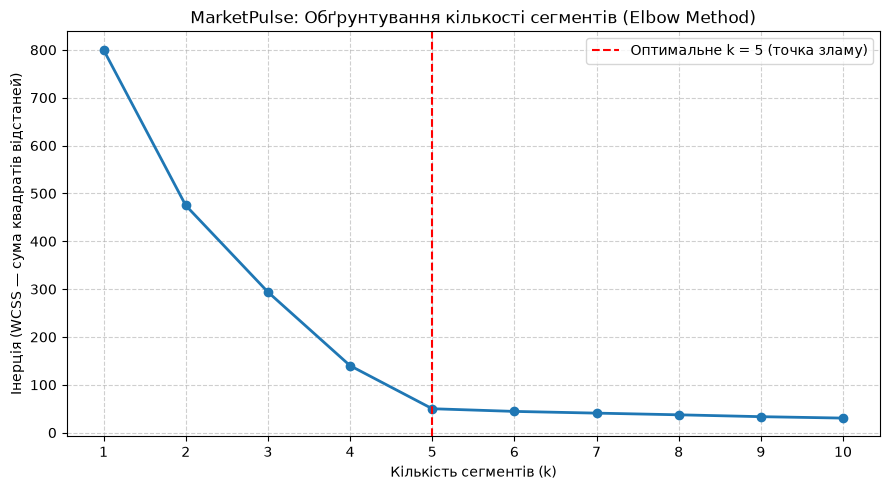

In [3]:
# ==========================================
# 2. Обґрунтування кількості сегментів: Метод ліктя (Elbow Method)
# ==========================================
k_values = range(1, 11)
inertias = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

optimal_k = 5

plt.figure(figsize=(9, 5))
plt.plot(
    k_values, inertias, marker="o", linestyle="-", color="#1f77b4", linewidth=2
)
plt.axvline(
    x=optimal_k,
    color="red",
    linestyle="--",
    label=f"Оптимальне k = {optimal_k} (точка зламу)",
)
plt.xticks(k_values)
plt.xlabel("Кількість сегментів (k)")
plt.ylabel("Інерція (WCSS — сума квадратів відстаней)")
plt.title("MarketPulse: Обґрунтування кількості сегментів (Elbow Method)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("marketpulse_elbow.png", dpi=300)
plt.show()

In [4]:
# ==========================================
# 3. Порівняння K-Means та Agglomerative Clustering
# ==========================================
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# Переводимо центроїди назад у вихідний масштаб для бізнес-інтерпретації
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)

agg = AgglomerativeClustering(n_clusters=optimal_k, linkage="ward")
df["Agg_Cluster"] = agg.fit_predict(X_scaled)

# Оцінка якості кластеризації
sil_kmeans = silhouette_score(X_scaled, df["KMeans_Cluster"])
sil_agg = silhouette_score(X_scaled, df["Agg_Cluster"])

print("=== Порівняння якості моделей ===")
print(f"K-Means Silhouette Score:                 {sil_kmeans:.4f}")
print(f"Agglomerative (Ward) Silhouette Score:    {sil_agg:.4f}\n")

print("=== Профілі сегментів (середні значення за K-Means) ===")
summary = df.groupby("KMeans_Cluster")[
    ["Annual_Income", "Spending_Score"]
].agg(["count", "mean"])
print(summary.round(2))

=== Порівняння якості моделей ===
K-Means Silhouette Score:                 0.6928
Agglomerative (Ward) Silhouette Score:    0.6914

=== Профілі сегментів (середні значення за K-Means) ===
               Annual_Income        Spending_Score       
                       count   mean          count   mean
KMeans_Cluster                                           
0                         80  28.76             80  80.33
1                         70  88.99             70  18.60
2                         80  24.23             80  19.96
3                         71  87.90             71  81.27
4                         99  54.71             99  49.77


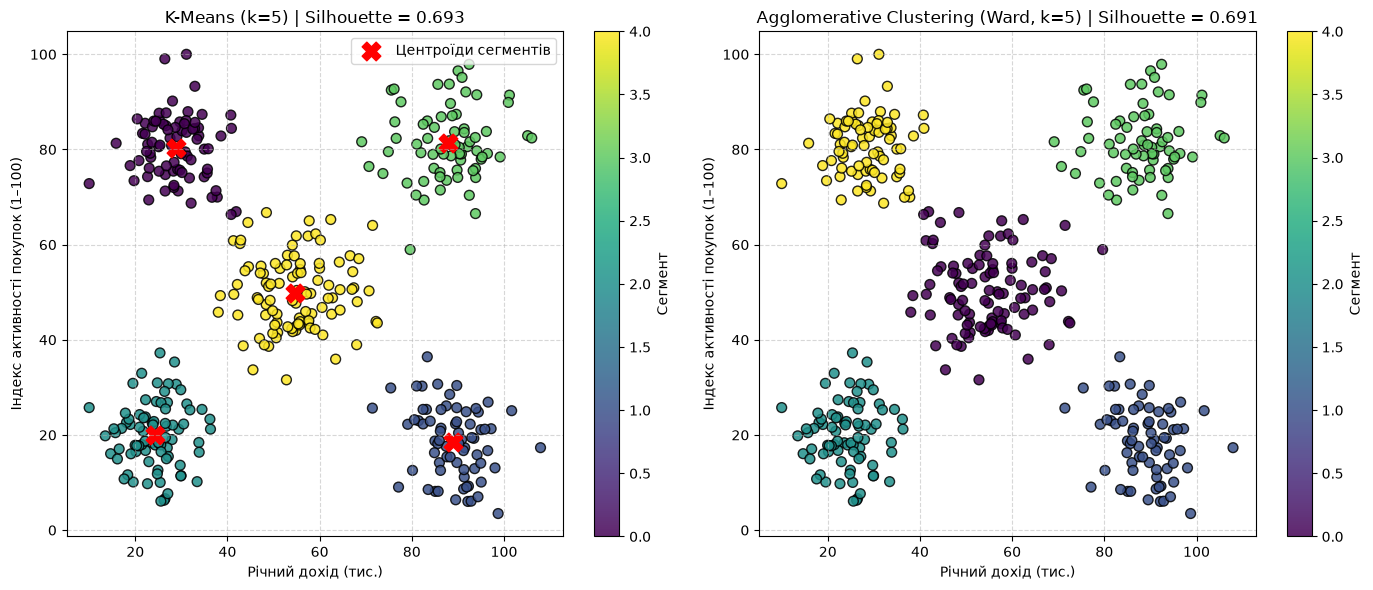

In [5]:
# ==========================================
# 4. Візуалізація та порівняння результатів
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# K-Means
sc1 = axes[0].scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    edgecolor="k",
    s=50,
    alpha=0.85,
)
axes[0].scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    c="red",
    marker="X",
    s=180,
    label="Центроїди сегментів",
)
axes[0].set_title(
    f"K-Means (k={optimal_k}) | Silhouette = {sil_kmeans:.3f}"
)
axes[0].set_xlabel("Річний дохід (тис.)")
axes[0].set_ylabel("Індекс активності покупок (1–100)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)
fig.colorbar(sc1, ax=axes[0], label="Сегмент")

# Agglomerative Clustering
sc2 = axes[1].scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Agg_Cluster"],
    cmap="viridis",
    edgecolor="k",
    s=50,
    alpha=0.85,
)
axes[1].set_title(
    f"Agglomerative Clustering (Ward, k={optimal_k}) | Silhouette = {sil_agg:.3f}"
)
axes[1].set_xlabel("Річний дохід (тис.)")
axes[1].set_ylabel("Індекс активності покупок (1–100)")
axes[1].grid(True, linestyle="--", alpha=0.5)
fig.colorbar(sc2, ax=axes[1], label="Сегмент")

plt.tight_layout()
plt.savefig("marketpulse_comparison.png", dpi=300)
plt.show()